Check CO2 emissions for ESM1.6 historical

In [1]:
import matplotlib.pyplot as plt
import nc_time_axis, cf_units, cftime
import numpy as np
import xarray as xr
import xarray_tools as xrt
import cartopy.crs as ccrs
import iris
from pathlib import Path
from notebook_metadata import create_savefig

savefig = create_savefig(dir='/scratch/tm70/mrd599/plots', nb='check_co2_emissions.ipynb')

In [2]:
from dask.distributed import Client
client = Client(threads_per_worker = 1)

In [3]:
# Non-default chunking helps when using fewer years, but causes failures with longer series
# d7 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc',
                    #    chunks={'sector':8, 'lat':360, 'lon':720})
d7 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc',
                       chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1})
ystart = '1849'
co2_cmip7 = d7.CO2_em_anthro.sel(time=slice(ystart, None))
area_cmip7 = xrt.get_area(co2_cmip7)

# d7a = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_AIR_anthro/gn/v20250421/CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc',
#                          chunks={'level':25, 'lat':360, 'lon':720})
d7a = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_AIR_anthro/gn/v20250421/CO2-em-AIR-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc',
                        chunks={'time':12, 'sector':-1, 'lat':-1, 'lon':-1})
co2_cmip7_air = d7a.CO2_em_AIR_anthro.sel(time=slice(ystart, None))

/jobfs/180075073.gadi-pbs/ipykernel_2636184/689557156.py:4: FutureWarning: In a future version of xarray the default value for data_vars will change from data_vars='all' to data_vars=None. This is likely to lead to different results when multiple datasets have matching variables with overlapping values. To opt in to new defaults and get rid of these warnings now use `set_options(use_new_combine_kwarg_defaults=True) or set data_vars explicitly.
  d7 = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04-18/atmos/mon/CO2_em_anthro/gn/v20250421/CO2-em-anthro_input4MIPs_emissions_CMIP_CEDS-CMIP-2025-04-18_gn_*.nc',
/jobfs/180075073.gadi-pbs/ipykernel_2636184/689557156.py:12: UserWarning: The specified chunks separate the stored chunks along dimension "time" starting at index 12. This could degrade performance. Instead, consider rechunking after loading.
  d7a = xr.open_mfdataset('/g/data/qv56/replicas/input4MIPs/CMIP7/CMIP/PNNL-JGCRI/CEDS-CMIP-2025-04

In [4]:
co2_cmip7_g = xrt.global_mean(co2_cmip7, area_cmip7).compute()
co2_cmip7_air_g = xrt.global_mean(co2_cmip7_air, area_cmip7).compute()

In [5]:
co2_cmip7_tot_g = (co2_cmip7_g.sum('sector') + co2_cmip7_air_g.sum('level')).compute()

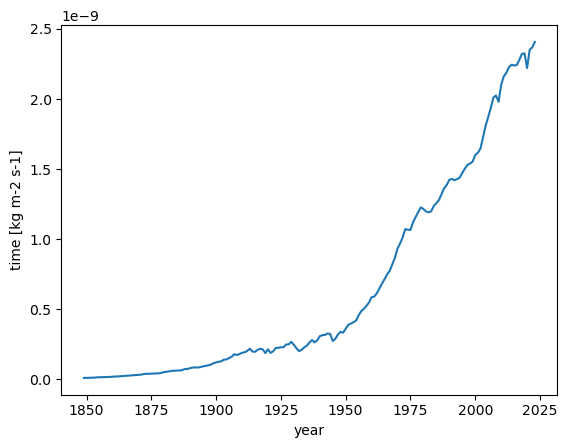

In [6]:
xrt.annual_mean(co2_cmip7_tot_g).plot()

In [7]:
co2_esm15 = xr.DataArray.from_iris(iris.load_cube('/g/data/p66/txz599/data/ancil/CMIP6/CO2_fluxes_ESM_1750_2014.anc'))
co2_esm15 = co2_esm15.rename({'latitude':'lat', 'longitude':'lon'})
area_esm15 = xr.open_dataset('/g/data/fs38/publications/CMIP6/CMIP/CSIRO/ACCESS-ESM1-5/piControl/r1i1p1f1/fx/areacella/gn/latest/areacella_fx_ACCESS-ESM1-5_piControl_r1i1p1f1_gn.nc').areacella


In [8]:
co2_esm16 = xr.DataArray.from_iris(iris.load_cube('/g/data/vk83/configurations/inputs/access-esm1p6/modern/historical-emissions/atmosphere/forcing/global.N96/2026.01.07/CO2_fluxes_1849_2023_cmip7.anc'))
co2_esm16 = co2_esm16.rename({'latitude':'lat', 'longitude':'lon'})


In [9]:
co2_esm15_g = xrt.global_mean(co2_esm15, area_esm15).compute()
co2_esm16_g = xrt.global_mean(co2_esm16, area_esm15).compute()

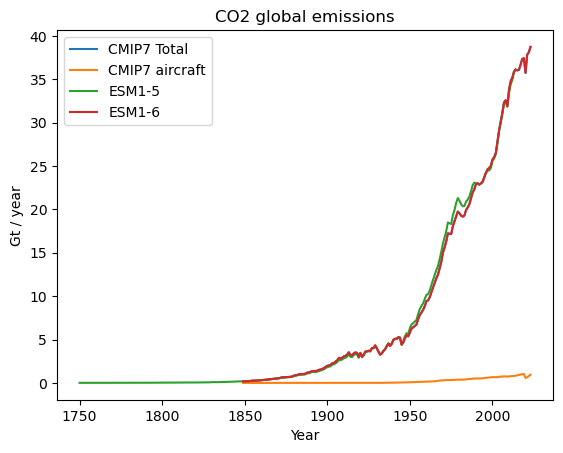

Process Dask Worker process (from Nanny):
Traceback (most recent call last):
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/asyncio/runners.py", line 118, in run
    return self._loop.run_until_complete(task)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/asyncio/base_events.py", line 691, in run_until_complete
    return future.result()
           ^^^^^^^^^^^^^^^
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/nanny.py", line 985, in run
    await worker.finished()
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/distributed/core.py", line 494, in finished
    await self._event_finished.wait()
  File "/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/asyncio/locks.py", line 212, in wait
    await fut
asyncio.exceptions.CancelledError

During handling of th

In [13]:
scale = 4 * np.pi * 6.371e6**2 * 365 * 86400 * 1e-12  # Gt/year

fig, axes = plt.subplots()
# xrt.annual_mean(co2_cmip6_g.sum('sector')).plot(label='CMIP6 surf')
# xrt.annual_mean(co2_cmip6_air_g.sum('level')).plot(label='CMIP6 air')
(scale*xrt.annual_mean(co2_cmip7_tot_g)).plot(label='CMIP7 Total')
# (scale*xrt.annual_mean(co2_cmip7_g.sum('sector'))).plot(label='CMIP7 surface')
(scale*xrt.annual_mean(co2_cmip7_air_g.sum('level'))).plot(label='CMIP7 aircraft')
# (scale*xrt.annual_mean(co2_esm15_g)).plot(label='ESM1-5')
(scale*xrt.annual_mean(co2_esm16_g)).plot(label='ESM1-6')
axes.legend()
axes.set_xlabel('Year')
axes.set_ylabel('Gt / year')
axes.set_title('CO2 global emissions')
# axes.set_xlim(2000,2015)
# axes.set_ylim(1.5e-9,2.3e-9)
savefig('co2_emissions.png')

In [11]:
co2_2000 = xrt.annual_mean(co2_cmip7.sel(time='2000').sum('sector')).compute()
co2_air_2000 = xrt.annual_mean(co2_cmip7_air.sel(time='2000').sum('level')).compute()

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/computation/apply_ufunc.py:820: RuntimeWarning: divide by zero encountered in log10
  result_data = func(*input_data)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/dask/_task_spec.py:768: RuntimeWarning: divide by zero encountered in log10
  return self.func(*new_argspec)


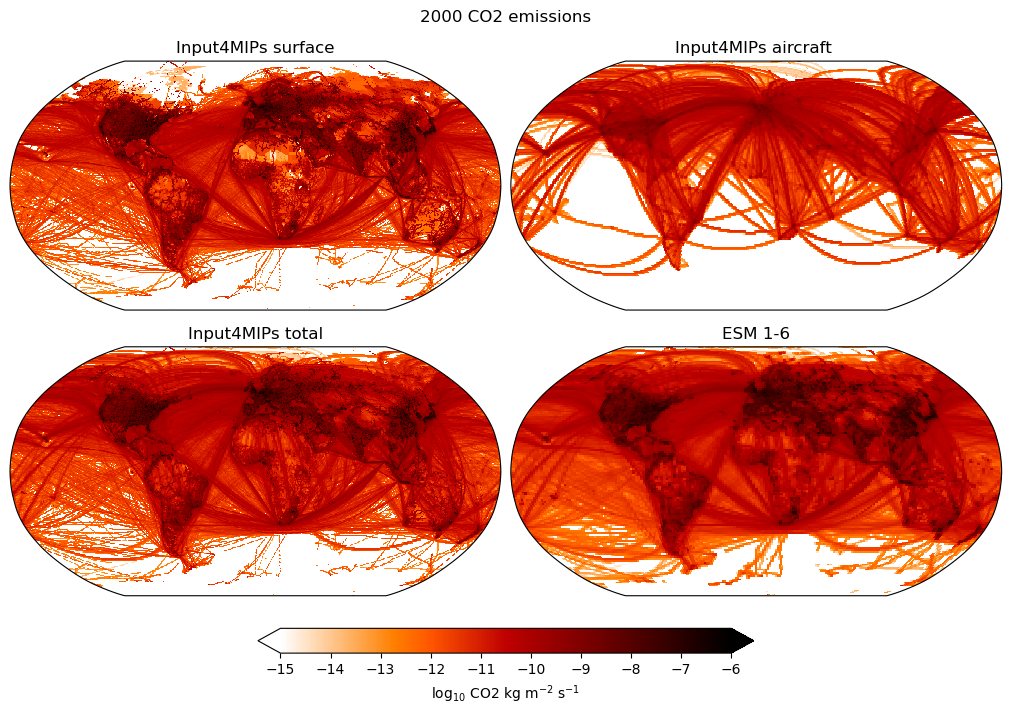

In [12]:
fig, axes = plt.subplots(2,2,layout='constrained', figsize=(10,7),subplot_kw={'projection': ccrs.Robinson()})
axes = axes.flatten()
vmin=-15
vmax=-6
fig.suptitle('2000 CO2 emissions')
ax = axes[0]
np.log10(co2_2000).plot(ax=ax,transform=ccrs.PlateCarree(),add_colorbar=False, cmap='gist_heat_r',vmin=vmin, vmax=vmax)
ax.set_title('Input4MIPs surface')
ax = axes[1]
np.log10(co2_air_2000).plot(ax=ax,transform=ccrs.PlateCarree(),add_colorbar=False, cmap='gist_heat_r',vmin=vmin, vmax=vmax)
ax.set_title('Input4MIPs aircraft ')
ax = axes[2]
np.log10(co2_2000 + co2_air_2000).plot(ax=ax,transform=ccrs.PlateCarree(),add_colorbar=False, cmap='gist_heat_r',vmin=vmin, vmax=vmax)
ax.set_title('Input4MIPs total')
ax = axes[3]
p = np.log10(xrt.annual_mean(co2_esm16.sel(time='2000'))).plot(ax=ax,transform=ccrs.PlateCarree(),add_colorbar=False, cmap='gist_heat_r',vmin=vmin, vmax=vmax)
ax.set_title('ESM 1-6')

cbar = fig.colorbar(p, ax=axes, orientation='horizontal', extend='both', shrink=0.5)
cbar.set_label(label='log$_{10}$ CO2 kg m$^{-2}$ s$^{-1}$')
savefig('co2_2000.png')